In [28]:
# pip install pandas numpy matplotlib seaborn scikit-learn openpyxl

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

In [29]:
df = pd.read_excel("Online Retail.xlsx")        # for Excel file

print(df.shape)
print(df.head())

(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  


In [30]:
df = df.dropna(subset=["CustomerID"])                 # need a customer ID
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]   # remove cancelled orders
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]       # remove returns / bad prices

df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]   # money spent per row
print("Rows after cleaning:", len(df))

Rows after cleaning: 397884


In [31]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)   # "today" for the dataset

rfm = df.groupby("CustomerID").agg(
    Recency   = ("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency = ("InvoiceNo", "nunique"),
    Monetary  = ("TotalPrice", "sum")
)

print(rfm.describe())

           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266460
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000


In [32]:
rfm_log = np.log1p(rfm)                      # log(1 + x), safe for zeros

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)   # mean = 0, std = 1

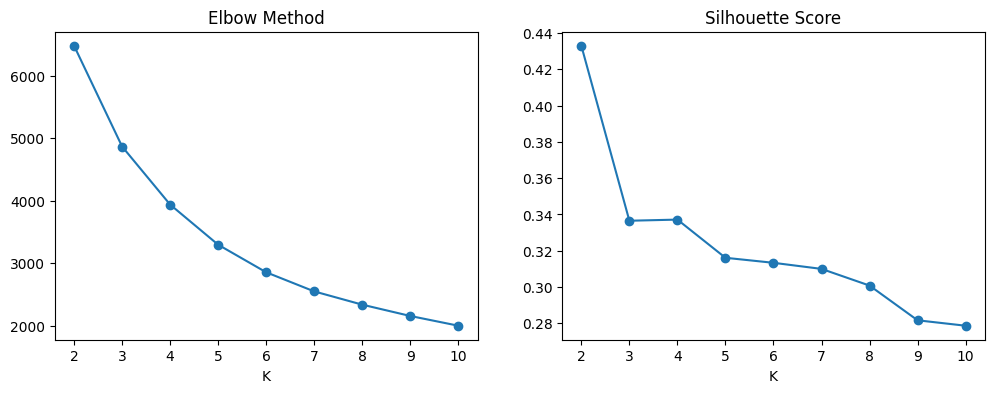

In [33]:
inertia, sil = [], []
K_range = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(rfm_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K_range, inertia, "o-"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("K")
ax[1].plot(K_range, sil, "o-");     ax[1].set_title("Silhouette Score"); ax[1].set_xlabel("K")
plt.show()

In [34]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["KMeans_Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm["KMeans_Cluster"].value_counts())

KMeans_Cluster
3    1612
2    1173
0     837
1     716
Name: count, dtype: int64


In [35]:
dbscan = DBSCAN(eps=0.5, min_samples=10)       # try eps = 0.3 to 0.8
rfm["DBSCAN_Cluster"] = dbscan.fit_predict(rfm_scaled)

print(rfm["DBSCAN_Cluster"].value_counts())    # -1 = noise/outliers

DBSCAN_Cluster
 0    2780
 1    1479
-1      79
Name: count, dtype: int64


Variance explained: 0.939


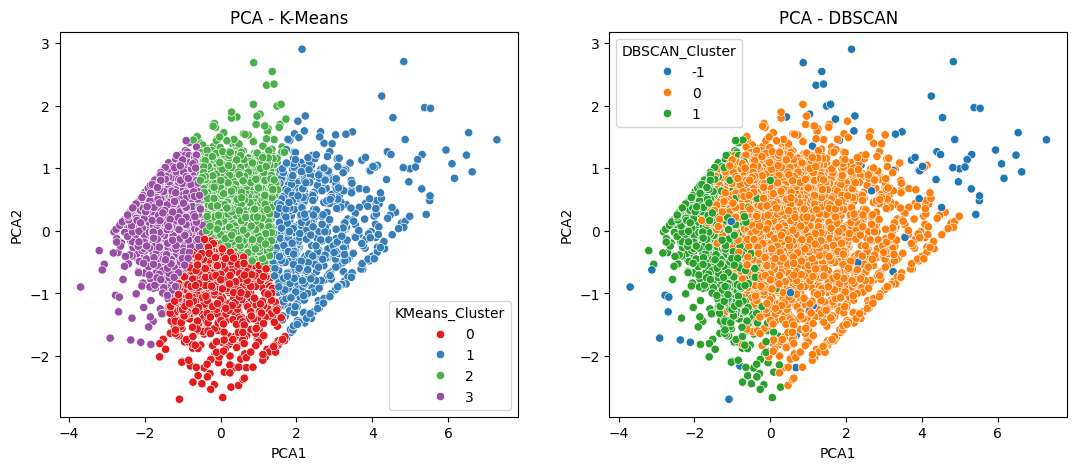

In [36]:
pca = PCA(n_components=2)
pca_data = pca.fit_transform(rfm_scaled)

rfm["PCA1"], rfm["PCA2"] = pca_data[:, 0], pca_data[:, 1]
print("Variance explained:", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=rfm, x="PCA1", y="PCA2", hue="KMeans_Cluster", palette="Set1", ax=ax[0])
ax[0].set_title("PCA - K-Means")
sns.scatterplot(data=rfm, x="PCA1", y="PCA2", hue="DBSCAN_Cluster", palette="tab10", ax=ax[1])
ax[1].set_title("PCA - DBSCAN")
plt.show()

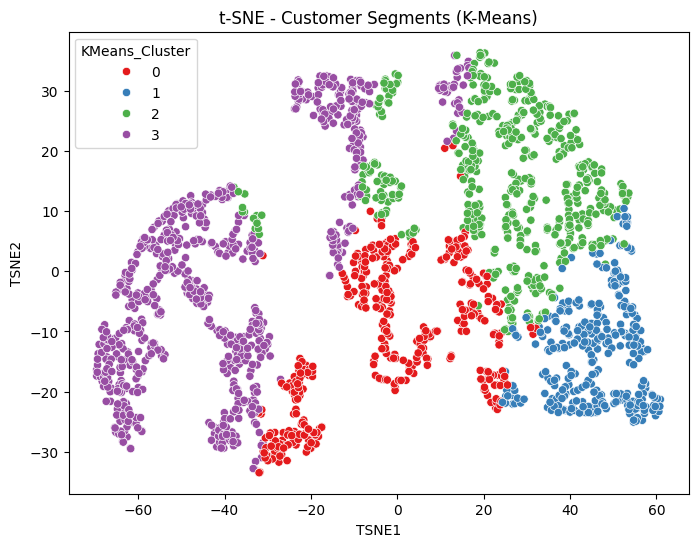

In [37]:
sample = rfm.sample(n=min(2000, len(rfm)), random_state=42)
sample_scaled = scaler.transform(np.log1p(sample[["Recency", "Frequency", "Monetary"]]))

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
tsne_data = tsne.fit_transform(sample_scaled)

sample["TSNE1"], sample["TSNE2"] = tsne_data[:, 0], tsne_data[:, 1]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="TSNE1", y="TSNE2", hue="KMeans_Cluster", palette="Set1")
plt.title("t-SNE - Customer Segments (K-Means)")
plt.show()

                Recency  Frequency  Monetary  Customers
KMeans_Cluster                                         
0                  18.1        2.1     551.8        837
1                  12.1       13.7    8074.3        716
2                  71.1        4.1    1802.8       1173
3                 182.5        1.3     343.5       1612


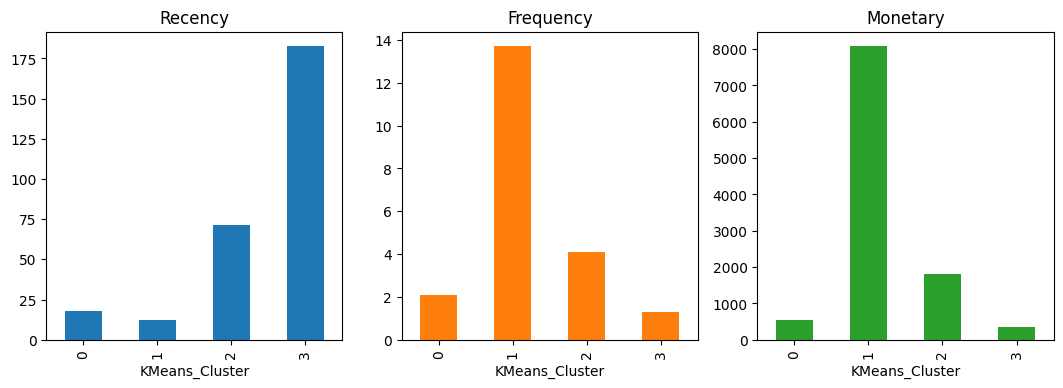

In [38]:
profile = rfm.groupby("KMeans_Cluster").agg(
    Recency   = ("Recency", "mean"),
    Frequency = ("Frequency", "mean"),
    Monetary  = ("Monetary", "mean"),
    Customers = ("Recency", "count")
).round(1)

print(profile)

profile[["Recency", "Frequency", "Monetary"]].plot(kind="bar", subplots=True,
                                                   layout=(1, 3), figsize=(13, 4), legend=False)
plt.show()

In [39]:
avg = profile[["Recency", "Frequency", "Monetary"]].mean()

def persona(row):
    low_r, high_f, high_m = row.Recency < avg.Recency, row.Frequency > avg.Frequency, row.Monetary > avg.Monetary
    if low_r and high_f and high_m: return "Champions"
    if low_r and not high_f:        return "New / Recent Customers"
    if not low_r and high_f:        return "At-Risk Loyalists"
    if not low_r and not high_f:    return "Lost / Hibernating"
    return "Potential Loyalists"

actions = {
    "Champions":              "Reward with VIP perks, early access, loyalty points; ask for reviews/referrals.",
    "New / Recent Customers": "Welcome series, onboarding offers, 2nd-purchase discount.",
    "At-Risk Loyalists":      "Win-back emails, 'We miss you' offers, personalised recommendations.",
    "Lost / Hibernating":     "Low-cost reactivation campaign or last-chance discount; otherwise stop spending.",
    "Potential Loyalists":    "Upsell, bundle deals, loyalty programme invitation."
}

profile["Persona"] = profile.apply(persona, axis=1)
profile["Marketing Action"] = profile["Persona"].map(actions)

print(profile[["Recency", "Frequency", "Monetary", "Customers", "Persona", "Marketing Action"]])

                Recency  Frequency  Monetary  Customers  \
KMeans_Cluster                                            
0                  18.1        2.1     551.8        837   
1                  12.1       13.7    8074.3        716   
2                  71.1        4.1    1802.8       1173   
3                 182.5        1.3     343.5       1612   

                               Persona  \
KMeans_Cluster                           
0               New / Recent Customers   
1                            Champions   
2                   Lost / Hibernating   
3                   Lost / Hibernating   

                                                 Marketing Action  
KMeans_Cluster                                                     
0               Welcome series, onboarding offers, 2nd-purchas...  
1               Reward with VIP perks, early access, loyalty p...  
2               Low-cost reactivation campaign or last-chance ...  
3               Low-cost reactivation campaign or la